<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Keep the review scope visible in an MFT timeline

A filesystem record can be marked deleted while its metadata and resident content remain in a collected Master File Table. We decode a small MFT, compare its two timestamp families, inspect the worker’s heuristic reasons, and trace which streams disappear when deleted records are excluded.

**This is an unchanged synthetic repository fixture**, not an incident collection or a real disk image. Names, paths, contents and timestamps were generated for known-answer tests. The file named `timestomped.exe` is deliberately constructed; its name is not evidence of detection. A heuristic flag is a review clue, not proof of tampering or attribution. The notebook does not access a live filesystem or recover non-resident content.

## One scope choice

`INCLUDE_DELETED` accepts **True** or **False**, default **True**. We always decode the complete fixture first, then select non-directory records for review. False retains only allocated non-directory records. This changes review coverage, not the parser or its heuristic.

In [1]:
INCLUDE_DELETED = True  # include unallocated records that still decode

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap

from notebook_support import finish, theme

assert type(INCLUDE_DELETED) is bool
provenance = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256(Path("fixtures/sample.mft").read_bytes()).hexdigest() == provenance["sha256"]
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mft/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-mft/notebooks/pyproject.toml.

## Decode once, then define the review population

The native release parses the local byte-for-byte fixture. Materializing `decoded` avoids repeating the read for charts. SQL retains the full `(host, entry, sequence)` identity, paths, allocation flags and diagnostics. The `$MFT` metadata record itself is not a directory, so it remains in the non-directory population.

Timestamp columns are timezone-free SQL `TIMESTAMP` values representing UTC instants decoded from NTFS FILETIME. We label them UTC and do not apply a local-time conversion. Missing timestamps or resident content remain NULL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mft' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-mft@v0.4.0');
CREATE TABLE decoded AS
SELECT * FROM mft.main.read_mft('fixtures/sample.mft',host := 'synthetic-host');
CREATE TABLE selected AS
SELECT * FROM decoded WHERE NOT is_dir AND ({{INCLUDE_DELETED}} OR is_allocated);
CREATE TABLE assessed AS
SELECT *,mft.main.timestomp(
 {'created':si_created,'modified':si_modified,'accessed':si_accessed,'mft_modified':si_mft_modified},
 {'created':fn_created,'modified':fn_modified,'accessed':fn_accessed,'mft_modified':fn_mft_modified}
) AS heuristic FROM selected;

,Count


In [4]:
%%sql coverage <<
SELECT count(*) AS decoded_records,count(*) FILTER(WHERE is_dir) AS directory_records,
 count(*) FILTER(WHERE NOT is_dir) AS non_directory_records,
 count(*) FILTER(WHERE NOT is_dir AND is_deleted) AS deleted_non_directory_records,
 (SELECT count(*) FROM selected) AS selected_records,
 (SELECT count(*) FROM selected WHERE is_deleted) AS retained_deleted_records,
 (SELECT count(*) FROM selected WHERE diagnostics IS NOT NULL) AS records_with_diagnostics
FROM decoded;

In [5]:
display(coverage)
r = coverage.iloc[0]
display(
    Markdown(
        f"The worker decodes **{int(r.decoded_records)} records**, "
        f"including **{int(r.directory_records)} directories**. "
        f"The selected population contains **{int(r.selected_records)} of "
        f"{int(r.non_directory_records)} non-directory records**. "
        f"Deleted records retained: **{int(r.retained_deleted_records)}**; "
        f"selected records with diagnostics: **{int(r.records_with_diagnostics)}**. "
        "An allocation filter can remove still-present evidence from this view; it does not erase the original fixture."
    )
)

,decoded_records,directory_records,non_directory_records,deleted_non_directory_records,selected_records,retained_deleted_records,records_with_diagnostics
0,10,3,7,1,7,1,1


The worker decodes **10 records**, including **3 directories**. The selected population contains **7 of 7 non-directory records**. Deleted records retained: **1**; selected records with diagnostics: **1**. An allocation filter can remove still-present evidence from this view; it does not erase the original fixture.

## Compare creation timestamps without collapsing the families

`$STANDARD_INFORMATION` (SI) and `$FILE_NAME` (FN) hold distinct timestamp fields. This plot keeps both creation values. An orange segment shows the interval between them, not a file lifetime. The table preserves full paths, missingness and diagnostic text; an orphan path is a reconstruction result, not a verified path on a live volume.

In [6]:
%%sql timeline <<
SELECT entry,sequence,file_name,full_path,is_allocated,is_deleted,
 si_created AS si_created_utc,fn_created AS fn_created_utc,
 date_diff('second',si_created,fn_created)/86400.0 AS fn_minus_si_days,
 is_timestomp_suspect,heuristic.reasons AS reasons,diagnostics
FROM assessed ORDER BY entry;

,entry,sequence,file_name,full_path,is_allocated,is_deleted,si_created_utc,fn_created_utc,fn_minus_si_days,is_timestomp_suspect,reasons,diagnostics
0,0,1,$MFT,$MFT,True,False,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],None
1,20,1,cmd.exe,Windows\System32\cmd.exe,True,False,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],None
2,21,1,big.bin,Windows\System32\big.bin,True,False,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],None
3,22,1,notes.txt,Windows\System32\notes.txt,True,False,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],None
4,23,2,deleted.log,Windows\System32\deleted.log,False,True,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],None
5,24,1,timestomped.exe,Windows\System32\timestomped.exe,True,False,2008-12-23 02:40:00.000,2020-09-13 12:26:40.000,4282.407407,True,"[si-creation-before-fn-creation, si-before-fn,...",None
6,25,1,orphan.dat,\$Orphan\999\orphan.dat,True,False,2020-09-13 12:26:40.500,2020-09-13 12:26:40.500,0.000000,False,[all-four-equal],orphan-parent


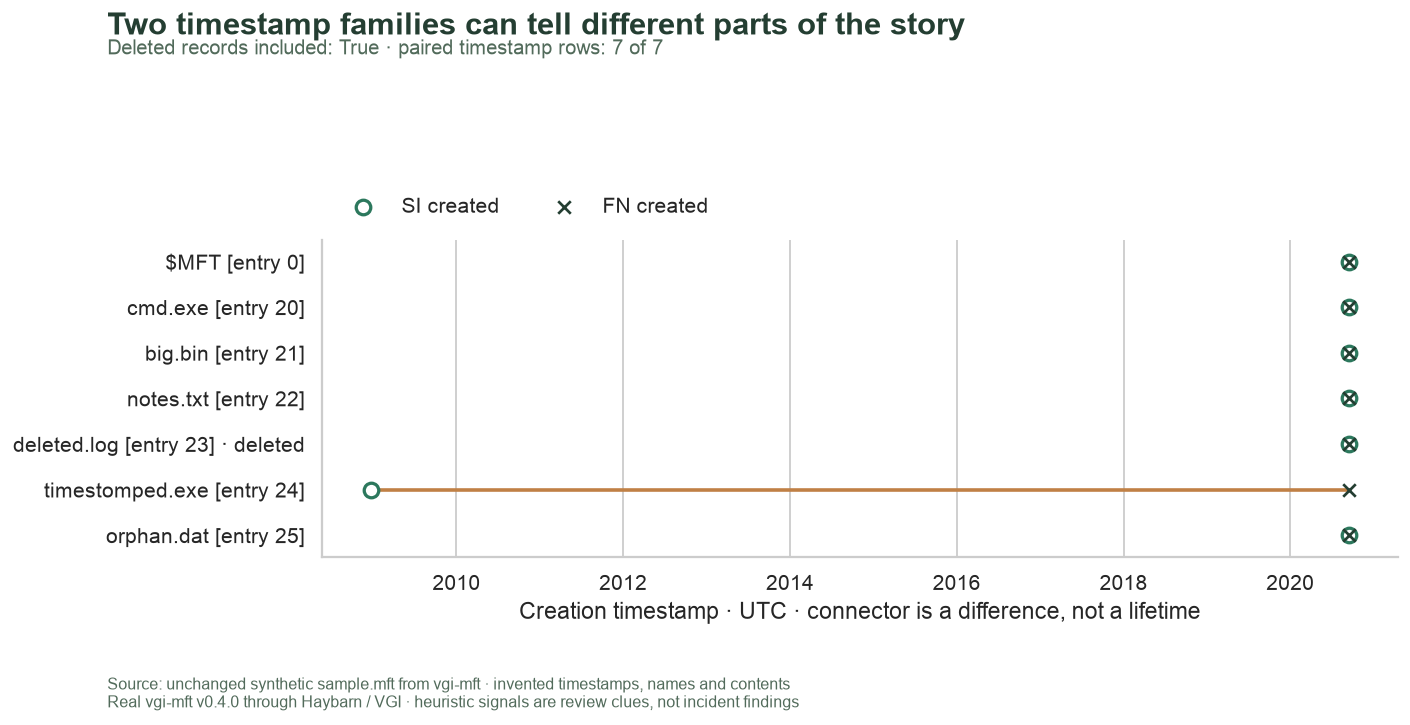

In [7]:
display(timeline)
plot = timeline.dropna(subset=["si_created_utc", "fn_created_utc"])
fig, ax = plt.subplots(figsize=(11.5, 5.6))
for i, row in enumerate(plot.itertuples()):
    ax.plot([row.si_created_utc, row.fn_created_utc], [i, i], color="#c08045", linewidth=2, zorder=1)
ax.scatter(
    plot.si_created_utc,
    list(range(len(plot))),
    marker="o",
    s=65,
    facecolors="white",
    edgecolors="#2c785d",
    linewidths=1.8,
    label="SI created",
    zorder=3,
)
ax.scatter(plot.fn_created_utc, list(range(len(plot))), marker="x", s=48, color="#243e32", label="FN created", zorder=4)
labels = [f"{r.file_name} [entry {r.entry}]" + (" · deleted" if r.is_deleted else "") for r in plot.itertuples()]
ax.set_yticks(range(len(plot)), labels)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Creation timestamp · UTC · connector is a difference, not a lifetime")
ax.grid(axis="y", visible=False)
ax.margins(x=0.05, y=0.08)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), frameon=False, ncol=2)
finish(
    fig,
    f"creation-timeline-deleted-{INCLUDE_DELETED}",
    "Two timestamp families can tell different parts of the story",
    f"Deleted records included: {INCLUDE_DELETED} · paired timestamp rows: {len(plot)} of {len(timeline)}",
)

## Expand streams, then inspect the reasons separately

One record can contain a primary `$DATA` stream and named alternate streams. `streams` accepts a relation of fixture BLOBs and selected entry IDs; it can return more or fewer rows than the file population. We aggregate it back by entry before joining to the timeline. Resident bytes are available here; non-resident logical size does not mean those bytes were recovered.

The worker’s reason list includes both flag-triggering and corroborating conditions. In particular, **all four SI timestamps being equal does not alone set the suspect flag**. We display it separately from the worker flag, path diagnostics, named streams and allocation state. These columns are not added into a risk score.

In [8]:
%%sql
CREATE TABLE stream_rows AS
SELECT * FROM mft.main.streams((
 SELECT b.content AS blob,s.entry
 FROM read_blob('fixtures/sample.mft') b CROSS JOIN selected s
));
CREATE TABLE stream_counts AS
SELECT entry,count(*) AS streams,count(*) FILTER(WHERE name IS NOT NULL) AS named_streams,
 count(*) FILTER(WHERE resident) AS resident_streams,
 sum(octet_length(data)) AS resident_bytes
FROM stream_rows GROUP BY entry;

,Count


In [9]:
%%sql stream_inventory <<
SELECT s.entry,a.file_name,s.name AS stream_name,s.logical_size AS logical_bytes,
 s.resident,octet_length(s.data) AS available_resident_bytes
FROM stream_rows s JOIN assessed a USING(entry)
ORDER BY s.entry,s.name NULLS FIRST;

In [10]:
display(stream_inventory)

,entry,file_name,stream_name,logical_bytes,resident,available_resident_bytes
0,20,cmd.exe,None,13,True,13
1,21,big.bin,None,1048576,False,<NA>
2,22,notes.txt,None,5,True,5
3,22,notes.txt,hidden,13,True,13
4,23,deleted.log,None,9,True,9
5,25,orphan.dat,None,4,True,4


In [11]:
%%sql signals <<
SELECT a.entry,a.file_name,a.is_deleted,a.is_timestomp_suspect,
 list_contains(a.heuristic.reasons,'si-creation-before-fn-creation') AS si_creation_before_fn,
 list_contains(a.heuristic.reasons,'si-before-fn') AS si_modification_before_fn,
 list_contains(a.heuristic.reasons,'zero-subsecond') AS whole_second_si,
 list_contains(a.heuristic.reasons,'all-four-equal') AS all_si_equal,
 a.diagnostics IS NOT NULL AS has_diagnostics,
 coalesce(s.named_streams,0)>0 AS has_named_stream,
 coalesce(s.streams,0) AS streams,coalesce(s.resident_streams,0) AS resident_streams,
 s.resident_bytes
FROM assessed a LEFT JOIN stream_counts s USING(entry) ORDER BY a.entry;

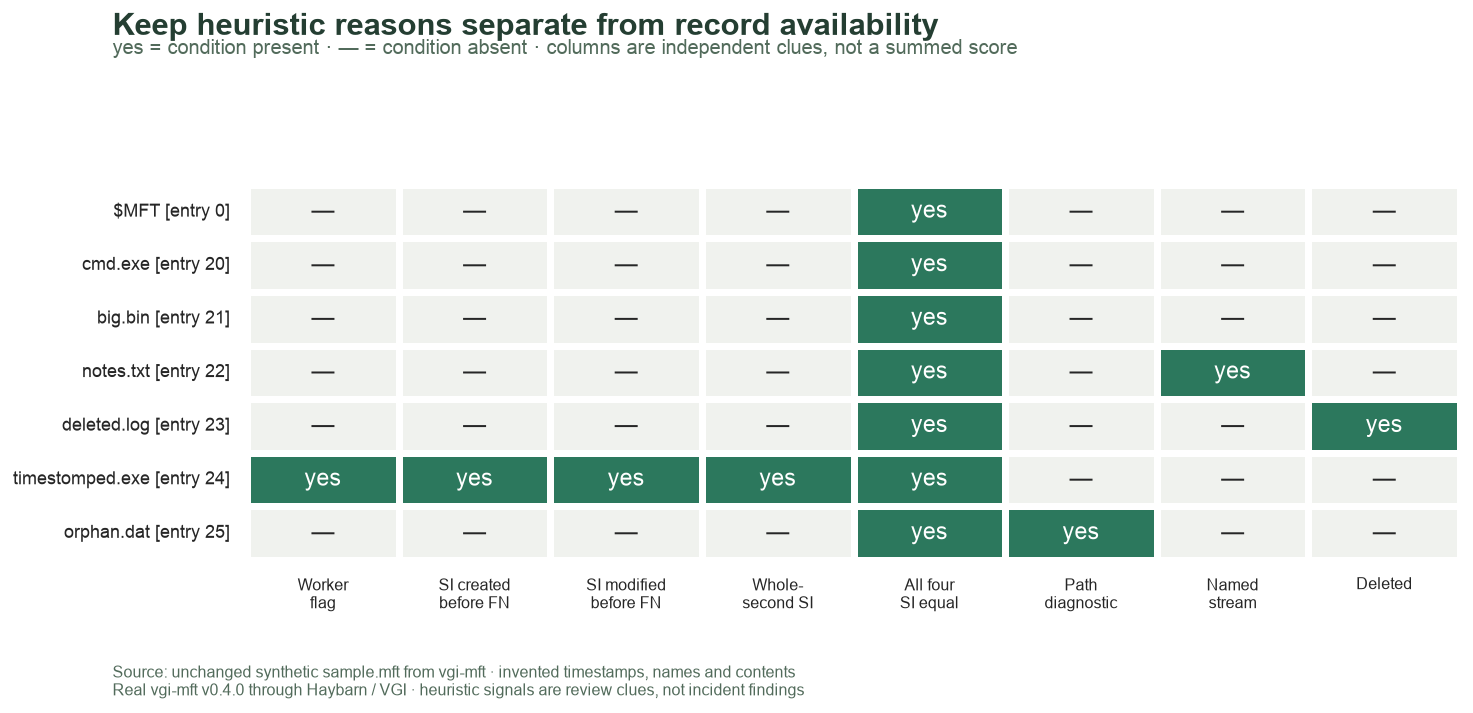

In [12]:
columns = {
    "is_timestomp_suspect": "Worker\nflag",
    "si_creation_before_fn": "SI created\nbefore FN",
    "si_modification_before_fn": "SI modified\nbefore FN",
    "whole_second_si": "Whole-\nsecond SI",
    "all_si_equal": "All four\nSI equal",
    "has_diagnostics": "Path\ndiagnostic",
    "has_named_stream": "Named\nstream",
    "is_deleted": "Deleted",
}
matrix = signals[list(columns)].astype(int)
annotations = matrix.map(lambda value: "yes" if value else "—")
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(
    matrix,
    ax=ax,
    annot=annotations,
    fmt="",
    vmin=0,
    vmax=1,
    cmap=ListedColormap(["#f0f2ee", "#2c785d"]),
    cbar=False,
    linewidths=3,
    linecolor="white",
    xticklabels=list(columns.values()),
    yticklabels=[f"{r.file_name} [entry {r.entry}]" for r in signals.itertuples()],
)
ax.tick_params(axis="x", rotation=0, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=10)
ax.set_xlabel("")
ax.set_ylabel("")
finish(
    fig,
    f"review-signals-deleted-{INCLUDE_DELETED}",
    "Keep heuristic reasons separate from record availability",
    "yes = condition present · — = condition absent · columns are independent clues, not a summed score",
)

In [13]:
flagged = int(signals.is_timestomp_suspect.sum())
corroborating = int((signals.all_si_equal & ~signals.is_timestomp_suspect).sum())
named = int(stream_inventory.stream_name.notna().sum())
resident = int(stream_inventory.resident.sum())
resident_bytes = int(stream_inventory.available_resident_bytes.sum())
display(
    Markdown(
        f"Worker-flagged records: **{flagged}**. "
        f"Records with all four SI values equal but no worker flag: **{corroborating}**. "
        f"Data streams in selected entries: **{len(stream_inventory)}**; named streams: **{named}**. "
        f"Available resident streams: **{resident}**, totaling **{resident_bytes} bytes**. "
        "An alternate stream or a deleted flag is not by itself malicious. "
        "The path diagnostic and missing non-resident content remain "
        "separate limits on what this fixture can establish."
    )
)

Worker-flagged records: **1**. Records with all four SI values equal but no worker flag: **6**. Data streams in selected entries: **6**; named streams: **1**. Available resident streams: **5**, totaling **44 bytes**. An alternate stream or a deleted flag is not by itself malicious. The path diagnostic and missing non-resident content remain separate limits on what this fixture can establish.

## Reconcile records, flags and stream fan-out

These checks validate stable record identity, selection coverage, agreement between the table flag and scalar heuristic, and resident stream byte accounting. They do not measure detection accuracy or certify a chain of custody. The hash check only confirms that the bundled synthetic fixture matches its recorded source bytes.

In [14]:
%%sql checks <<
SELECT 'decoded record identities unique' AS check_name,
 count(*)>0 AND count(*)=count(DISTINCT(host,entry,sequence)) AS passed FROM decoded
UNION ALL SELECT 'allocation flags are complementary',bool_and(is_allocated<>is_deleted) FROM decoded
UNION ALL SELECT 'selected population follows the visible scope',
 (SELECT count(*) FROM selected)=(SELECT count(*) FROM decoded WHERE NOT is_dir AND ({{INCLUDE_DELETED}} OR is_allocated))
UNION ALL SELECT 'selected records are not directories',bool_and(NOT is_dir) FROM selected
UNION ALL SELECT 'table flag agrees with scalar heuristic',bool_and(is_timestomp_suspect=heuristic.suspect) FROM assessed
UNION ALL SELECT 'strong reasons explain the worker flag',bool_and(heuristic.suspect=list_has_any(heuristic.reasons,
 ['si-creation-before-fn-creation','si-before-fn','zero-subsecond'])) FROM assessed
UNION ALL SELECT 'present timestamp columns have expected type',bool_and(typeof(si_created)='TIMESTAMP' AND typeof(fn_created)='TIMESTAMP') FROM selected
UNION ALL SELECT 'every stream belongs to selected entry',count(*)=0 FROM stream_rows s ANTI JOIN selected a USING(entry)
UNION ALL SELECT 'entry and stream name are unique',count(*)=count(DISTINCT(entry,name)) FROM stream_rows
UNION ALL SELECT 'resident stream bytes equal logical size',bool_and(data IS NOT NULL AND octet_length(data)=logical_size) FROM stream_rows WHERE resident
UNION ALL SELECT 'non-resident streams do not invent bytes',bool_and(data IS NULL) FROM stream_rows WHERE NOT resident
UNION ALL SELECT 'per-entry stream counts reconcile',coalesce(sum(streams),0)=(SELECT count(*) FROM stream_rows) FROM stream_counts;

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} invariants** pass for the selected scope. "
        "The timeline and stream view now have explicit coverage; "
        "neither turns a heuristic into an incident conclusion."
    )
)

,check_name,passed
0,decoded record identities unique,True
1,allocation flags are complementary,True
2,selected population follows the visible scope,True
3,selected records are not directories,True
4,table flag agrees with scalar heuristic,True
5,strong reasons explain the worker flag,True
6,present timestamp columns have expected type,True
7,every stream belongs to selected entry,True
8,entry and stream name are unique,True
9,resident stream bytes equal logical size,True


All **12 invariants** pass for the selected scope. The timeline and stream view now have explicit coverage; neither turns a heuristic into an incident conclusion.

## Try one change

Set `INCLUDE_DELETED` from **True** to **False**, restart and run all. Predict which row disappears from the timeline and signal matrix, then compare the resident stream count and available-byte total. Timestamps and reasons for retained records must not change. The complete decoded population remains the same; the selected view loses the unallocated record. Restore **True** for the saved default.

In [16]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>